# RQ14 — Conservative versus broad unlabeled universes

## Scientific question

**How does expanding the positive–unlabeled background from the explicit unlabeled set to a broader unresolved protein universe change positive recovery, score organization, and candidate prioritization?**

The frozen PU tasks differ only in the biological definition of `U`:

### PU conservative

\[
P=P_{\mathrm{core}},\qquad U=U_{\mathrm{explicit}}
\]

### PU broad

\[
P=P_{\mathrm{core}},\qquad
U=U_{\mathrm{explicit}}+U_{\mathrm{other\ unresolved}}
\]

`U` remains **unlabeled** in both tasks.

This notebook intentionally follows the operational notebook roadmap: RQ13 already contains the R/S PU curves and PU-gain surfaces, while RQ14 tests the **definition of the unlabeled universe**.


## Analysis contract

RQ14 separates two effects that must not be conflated.

### A. Native-universe contrast

Compare conservative and broad results at matched:

`R × S × representation × PU method × base learner`

This measures the **full consequence of changing the PU task definition**, including changes in split topology and native test composition.

These are matched-factor contrasts, **not entity-level paired effects**.

### B. Shared-entity contrast with native U references

For proteins present in the outer test of **both** tasks at the same R/S, compare the two fitted models on the exact same `P_core` proteins while each task retains its own native U reference distribution.

This controls positive test composition, but **does not yet isolate the training/model effect**, because the U reference distribution still differs between conservative and broad tasks.

### C. Common-reference contrast

Use the exact same shared `P_core` proteins **and** the exact same shared `U_explicit` proteins in both tasks.

For each fitted model, recompute U95/U99 and positive percentiles against its scores on that identical biological U reference set.

This is the cleanest RQ14 contrast for asking whether broad training itself changes separation between the original P/explicit-U problem.

### Primary diagnostic

\[
\Pr(s_P \ge Q_{0.95}(s_U))
\]

U95 remains primary because RQ12 showed that Elkan–Noto can create unresolved upper-tail ties at U99.


## Interpretation guardrails

- `U_other_unresolved` is not a negative class.
- High-scoring `U_other_unresolved` proteins are candidate-like, not confirmed positives.
- Native conservative-vs-broad contrasts are not paired entity-level effects.
- Shared-test comparisons use only exact-sequence identities present in both outer tests.
- Zero shared overlap is a valid Stage-08 split outcome and is reported as **not estimable**, never treated as a notebook failure.
- Absence of one broad-U stratum from a particular outer-test cell is also a valid split outcome.
- Candidate enrichment describes prioritization in score space, not biological prevalence.
- Canonical U99 is always interpreted alongside strict-U99 / clipping diagnostics.
- Representation × PU-method decomposition belongs to RQ15; RQ14 only checks whether conclusions are grossly method-dependent.
- R/S common-test sensitivity remains reserved for RQ16.


- Shared-P/native-U contrasts control positive composition but still use different U reference distributions.
- Claims about a training/model effect require the common-reference analysis using the same shared P and the same shared `U_explicit` entities.
- Candidate-tail stability is reported at both tie-aware top-5% and top-1%.


In [1]:
from pathlib import Path
from functools import lru_cache
import hashlib
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 400)
pd.set_option("display.width", 260)
pd.set_option("display.max_rows", 400)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASKS = ["pu_conservative", "pu_broad"]
METHODS = ["naive", "baggingpu", "elkan_noto"]
DEDICATED_METHODS = ["baggingpu", "elkan_noto"]

TASK_PATHS = {
    "pu_conservative": "pu_global/conservative",
    "pu_broad": "pu_global/broad",
}

METHOD_LABELS = {
    "naive": "Naive P-vs-U",
    "baggingpu": "BaggingPU",
    "elkan_noto": "Elkan–Noto",
}

PRIMARY = "fraction_P_above_U95"

NATIVE_METRICS = [
    "fraction_P_above_U90",
    "fraction_P_above_U95",
    "fraction_P_above_U99",
    "fraction_P_strictly_above_U99",
    "median_P_percentile_vs_U",
]

MODEL_KEYS = [
    "R", "S", "representation", "method", "algorithm"
]

PAIR_KEYS = [
    "R", "S", "representation", "method", "algorithm"
]

GAIN_KEYS = [
    "R", "S", "representation", "algorithm"
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_pu/stage12b2").is_dir()
            and (candidate / "results/analysis_pu/stage12a_qc").is_dir()
            and (candidate / "data/splits/pu_global").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate the PhageLysClass project root containing "
        "Stage12B2, Stage12A QC, and data/splits/pu_global."
    )

ROOT = find_project_root()
PU_DIR = ROOT / "results/analysis_pu/stage12b2"
PU_QC = ROOT / "results/analysis_pu/stage12a_qc"
SPLIT_ROOT = ROOT / "data/splits"
CACHE_DIR = ROOT / "results/analysis_pu/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)
print("PU_DIR:", PU_DIR)
print("SPLIT_ROOT:", SPLIT_ROOT)


ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass
PU_DIR: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/stage12b2
SPLIT_ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/data/splits


# 1. Validate the frozen PU benchmark


In [2]:
manifest_path = PU_DIR / "stage12b2_manifest.json"
if not manifest_path.is_file():
    raise FileNotFoundError(manifest_path)

manifest = json.loads(manifest_path.read_text())

if manifest.get("status") != "PASS":
    raise RuntimeError(
        f"Stage12B2 status is {manifest.get('status')}; RQ14 requires PASS."
    )

registry = pd.read_csv(
    PU_QC / "pu_completed_registry.tsv",
    sep="\t",
    low_memory=False,
)

required_registry = {
    "experiment_id", "task", "R", "S",
    "representation", "method", "algorithm", "path",
}
missing = required_registry - set(registry.columns)
if missing:
    raise KeyError(f"PU registry missing columns: {sorted(missing)}")

assert len(registry) == 768

coverage = (
    registry.groupby(
        ["task", "R", "S", "representation", "method", "algorithm"]
    )
    .size()
)

assert coverage.eq(1).all()
assert len(coverage) == 768

print("PU experiment families:", len(registry))
display(registry.groupby(["task", "method"]).size().unstack())


PU experiment families: 768


method,baggingpu,elkan_noto,naive
task,,,
pu_broad,128,128,128
pu_conservative,128,128,128


# 2. Identity and score utilities


In [3]:
HEX64_RE = re.compile(r"^[0-9a-fA-F]{64}$")

def _clean_text_series(series):
    return (
        series.astype("string")
        .fillna("")
        .str.strip()
        .astype(str)
    )

def _normalize_hash_series(series):
    return _clean_text_series(series).str.lower()

def _sequence_column(df):
    return next(
        (c for c in ["sequence", "sequence_norm", "seq"] if c in df.columns),
        None,
    )

def _derive_sequence_hash_from_sequence(df):
    seq_col = _sequence_column(df)
    if seq_col is None:
        return None

    seq = (
        _clean_text_series(df[seq_col])
        .str.replace(r"\s+", "", regex=True)
        .str.upper()
    )

    if seq.eq("").any():
        return None

    return seq.map(
        lambda s: hashlib.sha256(s.encode("utf-8")).hexdigest()
    )

def sequence_hash_series(df):
    if "sequence_sha256" in df.columns:
        s = _normalize_hash_series(df["sequence_sha256"])
        if s.ne("").all():
            return s

    derived = _derive_sequence_hash_from_sequence(df)
    if derived is not None:
        return derived.astype(str)

    if "sequence_uid" in df.columns:
        uid = _clean_text_series(df["sequence_uid"])
        nonempty = uid[uid.ne("")]
        if len(nonempty) and nonempty.map(
            lambda x: bool(HEX64_RE.fullmatch(x))
        ).all():
            return uid.str.lower()

    return None

def attach_sequence_key(df):
    out = df.copy()

    seq_hash = sequence_hash_series(out)
    if seq_hash is not None:
        out["sequence_key"] = seq_hash.astype(str)
        out["sequence_key_source"] = "sequence_sha256"
        return out

    if "sequence_uid" in out.columns:
        uid = _clean_text_series(out["sequence_uid"])
        if uid.ne("").all():
            out["sequence_key"] = uid
            out["sequence_key_source"] = "sequence_uid"
            return out

    if "entity_id" in out.columns:
        eid = _clean_text_series(out["entity_id"])
        if eid.ne("").all():
            out["sequence_key"] = eid
            out["sequence_key_source"] = "entity_id_fallback"
            return out

    raise KeyError(
        "Could not construct a stable sequence key. "
        f"Available columns: {list(out.columns)}"
    )

def identifier_views(df):
    views = {}

    seq_hash = sequence_hash_series(df)
    if seq_hash is not None:
        views["sequence_hash"] = seq_hash.astype(str)

    for c in ["sequence_uid", "entity_id", "sequence_entity_id"]:
        if c in df.columns:
            s = _clean_text_series(df[c])
            if s.ne("").all():
                views[c] = s

    return views

def resolve_join_identity(scores, meta):
    score_views = identifier_views(scores)
    meta_views = identifier_views(meta)

    candidate_semantics = [
        ("sequence_hash", "sequence_hash", 100),
        ("sequence_uid", "sequence_uid", 90),
        ("sequence_uid", "sequence_hash", 85),
        ("sequence_hash", "sequence_uid", 85),
        ("entity_id", "entity_id", 80),
        ("sequence_entity_id", "sequence_entity_id", 75),
        ("entity_id", "sequence_entity_id", 70),
        ("sequence_entity_id", "entity_id", 70),
    ]

    audit_rows = []

    for score_name, meta_name, priority in candidate_semantics:
        if score_name not in score_views or meta_name not in meta_views:
            continue

        skey = score_views[score_name].astype(str)
        mkey = meta_views[meta_name].astype(str)

        score_dup = int(skey.duplicated().sum())
        meta_dup = int(mkey.duplicated().sum())

        meta_set = set(mkey)
        matched = skey.isin(meta_set)
        n_matched = int(matched.sum())

        audit_rows.append({
            "score_identifier": score_name,
            "metadata_identifier": meta_name,
            "priority": priority,
            "n_score_rows": len(scores),
            "n_metadata_rows": len(meta),
            "n_matched_score_rows": n_matched,
            "coverage": n_matched / len(scores) if len(scores) else np.nan,
            "score_duplicate_keys": score_dup,
            "metadata_duplicate_keys": meta_dup,
        })

    if not audit_rows:
        raise RuntimeError(
            "No compatible score<->split identifier semantics found."
        )

    audit = pd.DataFrame(audit_rows).sort_values(
        ["coverage", "priority"],
        ascending=[False, False],
        kind="stable",
    )

    usable = audit[
        audit["score_duplicate_keys"].eq(0)
        & audit["metadata_duplicate_keys"].eq(0)
    ]

    if usable.empty:
        raise RuntimeError(
            "All candidate score<->metadata identifiers contain duplicates.\\n"
            + audit.to_string(index=False)
        )

    best = usable.iloc[0]

    if not np.isclose(float(best["coverage"]), 1.0):
        raise RuntimeError(
            "Could not obtain complete score<->split identity coverage.\\n"
            + audit.to_string(index=False)
        )

    return (
        score_views[str(best["score_identifier"])].astype(str),
        meta_views[str(best["metadata_identifier"])].astype(str),
        best.to_dict(),
        audit,
    )

def detect_score_col(df):
    for c in [
        "score_positive",
        "score",
        "corrected_score",
        "probability",
    ]:
        if c in df.columns:
            return c
    raise KeyError(
        f"No score column detected; columns={list(df.columns)}"
    )

def percentile_against(values, reference):
    values = np.asarray(values, dtype=float)
    reference = np.sort(np.asarray(reference, dtype=float))
    if len(reference) == 0:
        return np.full(len(values), np.nan)
    return np.searchsorted(reference, values, side="right") / len(reference)

def safe_quantile(values, q):
    values = pd.to_numeric(pd.Series(values), errors="coerce").dropna().to_numpy(float)
    if len(values) == 0:
        return np.nan
    return float(np.quantile(values, q))

def safe_spearman(a, b, min_n=3):
    x = pd.DataFrame({"a": a, "b": b}).dropna()
    if len(x) < min_n:
        return np.nan
    return float(x["a"].corr(x["b"], method="spearman"))

def jaccard(a, b):
    a, b = set(a), set(b)
    union = a | b
    if not union:
        return np.nan
    return len(a & b) / len(union)

def overlap_coefficient(a, b):
    a, b = set(a), set(b)
    if not a or not b:
        return np.nan
    return len(a & b) / min(len(a), len(b))

def top_quantile_pool(df, score_col="score", id_col="sequence_key", q=0.95):
    if len(df) == 0:
        return set(), np.nan, np.nan
    threshold = safe_quantile(df[score_col], q)
    if pd.isna(threshold):
        return set(), np.nan, np.nan
    mask = pd.to_numeric(df[score_col], errors="coerce") >= threshold
    pool = set(df.loc[mask, id_col].astype(str))
    return pool, threshold, float(mask.mean())


# 3. Load corrected RQ12 PU-native diagnostics


In [4]:
RQ12_NATIVE = CACHE_DIR / "rq12_pu_native_score_diagnostics.tsv"

def rebuild_native():
    rows = []

    for rec in registry.itertuples(index=False):
        p = Path(rec.path) / "outer_test_scores.parquet"
        if not p.is_file():
            raise FileNotFoundError(p)

        df = pd.read_parquet(p)
        if "observed_role" not in df.columns:
            raise KeyError(f"{p}: missing observed_role")

        score_col = detect_score_col(df)
        roles = df["observed_role"].astype(str).str.upper()
        scores = pd.to_numeric(df[score_col], errors="coerce")

        P = scores[roles.eq("P")].dropna().to_numpy(float)
        U = scores[roles.eq("U")].dropna().to_numpy(float)

        if len(P) == 0 or len(U) == 0:
            raise RuntimeError(
                f"{p}: native PU diagnostics require both P and U; "
                f"nP={len(P)}, nU={len(U)}"
            )

        q90, q95, q99 = np.quantile(U, [0.90, 0.95, 0.99])
        pp = percentile_against(P, U)

        rows.append({
            "experiment_id": rec.experiment_id,
            "task": rec.task,
            "R": int(rec.R),
            "S": int(rec.S),
            "representation": rec.representation,
            "method": rec.method,
            "algorithm": rec.algorithm,
            "n_P_test": len(P),
            "n_U_test": len(U),
            "fraction_P_above_U90": float(np.mean(P >= q90)),
            "fraction_P_above_U95": float(np.mean(P >= q95)),
            "fraction_P_above_U99": float(np.mean(P >= q99)),
            "fraction_P_strictly_above_U99": float(np.mean(P > q99)),
            "median_P_percentile_vs_U": float(np.median(pp)),
            "U_q99": float(q99),
            "U_fraction_at_score_1": float(
                np.mean(np.isclose(U, 1.0, rtol=0.0, atol=1e-12))
            ),
            "P_fraction_at_score_1": float(
                np.mean(np.isclose(P, 1.0, rtol=0.0, atol=1e-12))
            ),
        })

    return pd.DataFrame(rows)

if RQ12_NATIVE.is_file():
    native = pd.read_csv(
        RQ12_NATIVE,
        sep="\t",
        low_memory=False,
    )
    native_source = "RQ12 corrected cache"
else:
    native = rebuild_native()
    native_source = "reconstructed from frozen outer-test scores"

assert len(native) == 768

missing = set(NATIVE_METRICS) - set(native.columns)
if missing:
    raise KeyError(
        f"RQ12 native table missing columns: {sorted(missing)}"
    )

print("Native source:", native_source)
print("Native rows:", len(native))
display(native.head())


Native source: RQ12 corrected cache
Native rows: 768


,experiment_id,task,R,S,representation,method,algorithm,n_P_test,n_U_test,median_P_score,median_U_score,median_score_gap_P_minus_U,mean_P_percentile_vs_U,median_P_percentile_vs_U,fraction_P_above_U90,fraction_P_above_U95,fraction_P_above_U99,fraction_P_strictly_above_U90,fraction_P_strictly_above_U95,fraction_P_strictly_above_U99,fraction_U_score_ge_050,fraction_P_score_ge_050,U_q90,U_q95,U_q99,U_tie_fraction_at_q90,U_tie_fraction_at_q95,U_tie_fraction_at_q99,P_tie_fraction_at_Uq90,P_tie_fraction_at_Uq95,P_tie_fraction_at_Uq99,U_fraction_at_score_1,P_fraction_at_score_1,P_recovery_tie_component_U90,P_recovery_tie_component_U95,P_recovery_tie_component_U99
0,PU__pu_broad__R90__S90__roxy_48__naive__LR,pu_broad,90,90,roxy_48,naive,LR,1428,64386,0.842071,0.125035,0.717037,0.913919,0.969279,0.759804,0.606443,0.263305,0.759804,0.606443,0.263305,0.182928,0.867647,0.664297,0.787535,0.916668,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
1,PU__pu_broad__R90__S90__roxy_48__naive__XGB,pu_broad,90,90,roxy_48,naive,XGB,1428,64386,0.896035,0.003444,0.892591,0.952163,0.993935,0.887955,0.814426,0.585434,0.887955,0.814426,0.585434,0.035256,0.768908,0.152671,0.366174,0.833592,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
2,PU__pu_broad__R90__S90__roxy_48__baggingpu__LR,pu_broad,90,90,roxy_48,baggingpu,LR,1428,64386,0.843071,0.127132,0.715939,0.914066,0.969512,0.757703,0.607843,0.264006,0.757703,0.607843,0.264006,0.184419,0.866947,0.666161,0.788119,0.916082,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
3,PU__pu_broad__R90__S90__roxy_48__baggingpu__XGB,pu_broad,90,90,roxy_48,baggingpu,XGB,1428,64386,0.974142,0.024552,0.949590,0.952396,0.993089,0.876050,0.799720,0.567927,0.876050,0.799720,0.567927,0.108564,0.881653,0.534183,0.771410,0.961027,0.0,0.00000,0.00000,0.0,0.000000,0.000000,0.00000,0.000000,0.0,0.000000,0.000000
4,PU__pu_broad__R90__S90__roxy_48__elkan_noto__LR,pu_broad,90,90,roxy_48,elkan_noto,LR,1428,64386,1.000000,0.163790,0.836210,0.925649,1.000000,0.759804,0.642157,0.642157,0.759804,0.000000,0.000000,0.256593,0.912465,0.870198,1.000000,1.000000,0.0,0.05919,0.05919,0.0,0.642157,0.642157,0.05919,0.642157,0.0,0.642157,0.642157


# 4. Verify the Stage-07 biological relationship between conservative and broad universes


In [5]:
def split_dir(task, r, s):
    return SPLIT_ROOT / TASK_PATHS[task] / f"R{r}_S{s}"

def canonical_state_from_columns(df):
    if "sequence_state" in df.columns:
        state = _clean_text_series(df["sequence_state"]).str.lower()
    else:
        state = pd.Series("", index=df.index, dtype=object)

    role_col = next(
        (c for c in ["pu_role", "pnu_role", "observed_role"] if c in df.columns),
        None,
    )
    role = (
        _clean_text_series(df[role_col]).str.upper()
        if role_col is not None
        else pd.Series("", index=df.index, dtype=object)
    )

    exact_map = {
        "p_core": "P_core",
        "u_explicit": "U_explicit",
        "u_other_unresolved": "U_other_unresolved",
    }

    out = state.map(exact_map).fillna("unknown").astype(object)

    out.loc[
        out.eq("unknown") & role.eq("P")
    ] = "P_core"

    out.loc[
        out.eq("unknown") & role.eq("U")
    ] = "U_unresolved_state"

    return out

def read_full_split_universe(task, r):
    # S does not change the Stage-07 entity universe.
    d = split_dir(task, r, 90)
    combined = d / "dataset_with_split.tsv.gz"

    if combined.is_file():
        df = pd.read_csv(
            combined,
            sep="\t",
            low_memory=False,
        )
    else:
        parts = []
        for name in ["train.tsv.gz", "test.tsv.gz"]:
            p = d / name
            if not p.is_file():
                raise FileNotFoundError(p)
            parts.append(
                pd.read_csv(
                    p,
                    sep="\t",
                    low_memory=False,
                )
            )
        df = pd.concat(parts, ignore_index=True)

    df = attach_sequence_key(df)
    df["canonical_state"] = canonical_state_from_columns(df)

    if df["sequence_key"].duplicated().any():
        dup = int(df["sequence_key"].duplicated().sum())
        raise RuntimeError(
            f"{task} R{r}: duplicate exact-sequence keys in Stage-07 universe: {dup}"
        )

    return df

stage07_frames = {}
stage07_state_maps = {}
universe_rows = []
universe_set_rows = []

for r in R_LEVELS:
    for task in TASKS:
        df = read_full_split_universe(task, r)
        stage07_frames[(task, r)] = df
        stage07_state_maps[(task, r)] = (
            df.set_index("sequence_key")["canonical_state"].to_dict()
        )

        counts = df["canonical_state"].value_counts().to_dict()

        universe_rows.append({
            "task": task,
            "R": r,
            "n_total": len(df),
            "n_P_core": counts.get("P_core", 0),
            "n_U_explicit": counts.get("U_explicit", 0),
            "n_U_other_unresolved": counts.get("U_other_unresolved", 0),
            "n_unresolved_state": (
                counts.get("unknown", 0)
                + counts.get("U_unresolved_state", 0)
            ),
        })

    cons = stage07_frames[("pu_conservative", r)]
    broad = stage07_frames[("pu_broad", r)]

    for state in ["P_core", "U_explicit"]:
        a = set(
            cons.loc[
                cons["canonical_state"].eq(state),
                "sequence_key",
            ].astype(str)
        )
        b = set(
            broad.loc[
                broad["canonical_state"].eq(state),
                "sequence_key",
            ].astype(str)
        )

        universe_set_rows.append({
            "R": r,
            "state": state,
            "n_conservative": len(a),
            "n_broad": len(b),
            "intersection": len(a & b),
            "union": len(a | b),
            "jaccard": len(a & b) / len(a | b) if (a | b) else np.nan,
            "sets_identical": a == b,
        })

universe_composition = pd.DataFrame(universe_rows)
universe_identity = pd.DataFrame(universe_set_rows)

display(universe_composition)
display(universe_identity)

assert universe_identity["sets_identical"].all()

for r in R_LEVELS:
    cons = universe_composition[
        universe_composition["task"].eq("pu_conservative")
        & universe_composition["R"].eq(r)
    ].iloc[0]

    broad = universe_composition[
        universe_composition["task"].eq("pu_broad")
        & universe_composition["R"].eq(r)
    ].iloc[0]

    assert cons["n_P_core"] > 0
    assert broad["n_P_core"] > 0
    assert cons["n_U_explicit"] > 0
    assert broad["n_U_explicit"] > 0
    assert cons["n_U_other_unresolved"] == 0
    assert broad["n_U_other_unresolved"] > 0

print("PASS — Stage-07 P_core/U_explicit identities verified.")


,task,R,n_total,n_P_core,n_U_explicit,n_U_other_unresolved,n_unresolved_state
0,pu_conservative,90,152820,5013,147807,0,0
1,pu_broad,90,222235,5013,147807,69415,0
2,pu_conservative,70,123073,3654,119419,0,0
3,pu_broad,70,175249,3654,119419,52176,0
4,pu_conservative,50,103912,2555,101357,0,0
5,pu_broad,50,143736,2555,101357,39824,0
6,pu_conservative,30,89153,1705,87448,0,0
7,pu_broad,30,117481,1705,87448,28328,0


,R,state,n_conservative,n_broad,intersection,union,jaccard,sets_identical
0,90,P_core,5013,5013,5013,5013,1.0,True
1,90,U_explicit,147807,147807,147807,147807,1.0,True
2,70,P_core,3654,3654,3654,3654,1.0,True
3,70,U_explicit,119419,119419,119419,119419,1.0,True
4,50,P_core,2555,2555,2555,2555,1.0,True
5,50,U_explicit,101357,101357,101357,101357,1.0,True
6,30,P_core,1705,1705,1705,1705,1.0,True
7,30,U_explicit,87448,87448,87448,87448,1.0,True


PASS — Stage-07 P_core/U_explicit identities verified.


The Stage-07 identity check is intentionally strict. If this fails, conservative and broad are not the frozen biological comparison RQ14 is supposed to analyze.

All **outer-test** availability checks below are different: missing shared entities or missing U sub-strata are valid consequences of Stage-08 whole-task homology splitting and therefore become `NA`, not fatal errors.


# 5. Quantify how much broader the broad universe is


In [6]:
breadth_rows = []

for r in R_LEVELS:
    cons = universe_composition[
        universe_composition["task"].eq("pu_conservative")
        & universe_composition["R"].eq(r)
    ].iloc[0]

    broad = universe_composition[
        universe_composition["task"].eq("pu_broad")
        & universe_composition["R"].eq(r)
    ].iloc[0]

    extra = int(broad["n_U_other_unresolved"])
    broad_u_total = int(
        broad["n_U_explicit"]
        + broad["n_U_other_unresolved"]
    )

    breadth_rows.append({
        "R": r,
        "conservative_total": int(cons["n_total"]),
        "broad_total": int(broad["n_total"]),
        "U_explicit": int(cons["n_U_explicit"]),
        "added_U_other_unresolved": extra,
        "broad_total_over_conservative": (
            broad["n_total"] / cons["n_total"]
        ),
        "extra_U_over_U_explicit": (
            extra / cons["n_U_explicit"]
            if cons["n_U_explicit"] else np.nan
        ),
        "U_other_fraction_of_broad_U": (
            extra / broad_u_total
            if broad_u_total else np.nan
        ),
    })

breadth = pd.DataFrame(breadth_rows)
display(breadth)


,R,conservative_total,broad_total,U_explicit,added_U_other_unresolved,broad_total_over_conservative,extra_U_over_U_explicit,U_other_fraction_of_broad_U
0,90,152820,222235,147807,69415,1.454227,0.469633,0.319558
1,70,123073,175249,119419,52176,1.423944,0.436915,0.304065
2,50,103912,143736,101357,39824,1.383247,0.392908,0.282078
3,30,89153,117481,87448,28328,1.317746,0.323941,0.244679


# 6. Native conservative-versus-broad PU-recovery contrasts


In [7]:
native_contrast_parts = []

for metric in NATIVE_METRICS:
    wide = (
        native.pivot_table(
            index=MODEL_KEYS,
            columns="task",
            values=metric,
            aggfunc="first",
        )
        .reset_index()
    )

    if not set(TASKS) <= set(wide.columns):
        raise RuntimeError(
            f"Missing PU tasks for native metric {metric}"
        )

    tmp = wide[MODEL_KEYS].copy()
    tmp["metric"] = metric
    tmp["conservative"] = wide["pu_conservative"]
    tmp["broad"] = wide["pu_broad"]
    tmp["delta_broad_minus_conservative"] = (
        tmp["broad"] - tmp["conservative"]
    )
    native_contrast_parts.append(tmp)

native_contrasts = pd.concat(
    native_contrast_parts,
    ignore_index=True,
)

primary_native = native_contrasts[
    native_contrasts["metric"].eq(PRIMARY)
].copy()

print("Primary native contrasts:", len(primary_native))
assert len(primary_native) == 384

display(
    primary_native.groupby("method")
    ["delta_broad_minus_conservative"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reindex(METHODS)
)


Primary native contrasts: 384


,n,mean,median,q25,q75,fraction_positive,fraction_negative,fraction_practical_tie
method,,,,,,,,
naive,128,-0.068109,-0.053845,-0.119389,-0.022312,0.046875,0.953125,0.218750
baggingpu,128,-0.065970,-0.056167,-0.117188,-0.018982,0.046875,0.953125,0.257812
elkan_noto,128,-0.053677,-0.047382,-0.079691,-0.019892,0.046875,0.953125,0.250000


# 7. Native universe effect across R and S


,method,R,mean,median,q25,q75
0,baggingpu,30,-0.076156,-0.058967,-0.120356,-0.032500
1,baggingpu,50,-0.057752,-0.056648,-0.090946,-0.017826
2,baggingpu,70,-0.070641,-0.051934,-0.122270,-0.016821
3,baggingpu,90,-0.059329,-0.047093,-0.121746,-0.013417
4,elkan_noto,30,-0.066523,-0.059615,-0.087968,-0.033864
5,elkan_noto,50,-0.042948,-0.041326,-0.061058,-0.012481
6,elkan_noto,70,-0.054930,-0.050880,-0.081548,-0.021013
7,elkan_noto,90,-0.050308,-0.037927,-0.082262,-0.015738
8,naive,30,-0.077040,-0.063925,-0.119389,-0.033864
9,naive,50,-0.060173,-0.050637,-0.100506,-0.024296


,method,S,mean,median,q25,q75
0,baggingpu,30,-0.064359,-0.053633,-0.115401,-0.016749
1,baggingpu,50,-0.066431,-0.051275,-0.124144,-0.017605
2,baggingpu,70,-0.062790,-0.056117,-0.096028,-0.022081
3,baggingpu,90,-0.070298,-0.059725,-0.121210,-0.023715
4,elkan_noto,30,-0.046875,-0.039804,-0.078188,-0.016097
5,elkan_noto,50,-0.052058,-0.048476,-0.069526,-0.019453
6,elkan_noto,70,-0.057400,-0.044689,-0.086892,-0.021518
7,elkan_noto,90,-0.058377,-0.055479,-0.078481,-0.024150
8,naive,30,-0.064233,-0.056709,-0.111872,-0.019050
9,naive,50,-0.068651,-0.048476,-0.120979,-0.019453


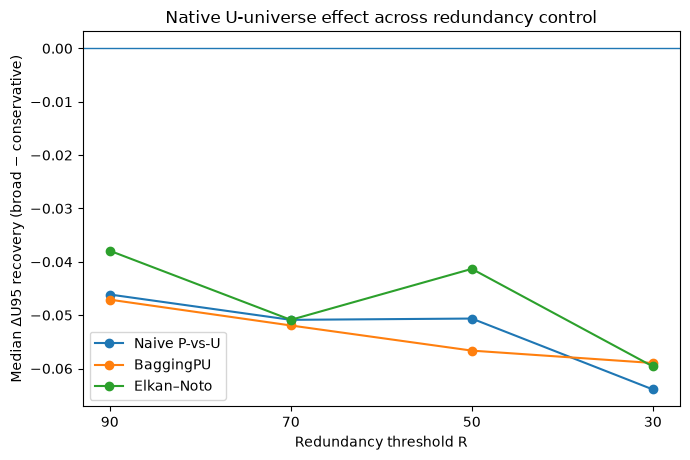

In [8]:
native_by_R = (
    primary_native.groupby(["method", "R"])
    ["delta_broad_minus_conservative"]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

native_by_S = (
    primary_native.groupby(["method", "S"])
    ["delta_broad_minus_conservative"]
    .agg(
        mean="mean",
        median="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
    )
    .reset_index()
)

display(native_by_R)
display(native_by_S)

fig, ax = plt.subplots(figsize=(7.0, 4.7))

for method in METHODS:
    g = (
        native_by_R[native_by_R["method"].eq(method)]
        .assign(order=lambda x: x["R"].map({90: 0, 70: 1, 50: 2, 30: 3}))
        .sort_values("order")
    )
    ax.plot(
        g["R"].astype(str),
        g["median"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median ΔU95 recovery (broad − conservative)")
ax.set_title("Native U-universe effect across redundancy control")
ax.legend()
plt.tight_layout()
plt.show()


# 8. Cross-metric native universe effect


In [9]:
native_metric_summary = (
    native_contrasts.groupby(["metric", "method"])
    ["delta_broad_minus_conservative"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_negative=lambda x: (x < 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reset_index()
)

display(native_metric_summary)


,metric,method,n,mean,median,median_abs,fraction_positive,fraction_negative,fraction_practical_tie
0,fraction_P_above_U90,baggingpu,128,-0.050296,-0.039357,0.039357,0.078125,0.921875,0.328125
1,fraction_P_above_U90,elkan_noto,128,-0.056043,-0.037106,0.037106,0.046875,0.953125,0.328125
2,fraction_P_above_U90,naive,128,-0.056043,-0.037106,0.037106,0.046875,0.953125,0.328125
3,fraction_P_above_U95,baggingpu,128,-0.065970,-0.056167,0.056167,0.046875,0.953125,0.257812
4,fraction_P_above_U95,elkan_noto,128,-0.053677,-0.047382,0.047382,0.046875,0.953125,0.250000
5,fraction_P_above_U95,naive,128,-0.068109,-0.053845,0.053845,0.046875,0.953125,0.218750
6,fraction_P_above_U99,baggingpu,128,-0.088960,-0.086470,0.086470,0.000000,1.000000,0.015625
7,fraction_P_above_U99,elkan_noto,128,-0.044376,-0.039229,0.039229,0.085938,0.914062,0.179688
8,fraction_P_above_U99,naive,128,-0.085274,-0.080574,0.080574,0.000000,1.000000,0.007812
9,fraction_P_strictly_above_U99,baggingpu,128,-0.088960,-0.086470,0.086470,0.000000,1.000000,0.015625


Canonical U99 is secondary. A broad-versus-conservative signal that exists only for canonical U99 but disappears for strict U99 is not interpreted as stronger resolved ranking, especially for Elkan–Noto.


# 9. Load Stage-08 outer-test metadata and attach Stage-07 state membership


In [10]:
@lru_cache(maxsize=None)
def load_test_metadata(task, r, s):
    p = split_dir(task, r, s) / "test.tsv.gz"
    if not p.is_file():
        raise FileNotFoundError(p)

    df = pd.read_csv(
        p,
        sep="\t",
        low_memory=False,
    )
    df = attach_sequence_key(df)

    if df["sequence_key"].duplicated().any():
        raise RuntimeError(
            f"{p}: duplicate sequence_key values in outer test."
        )

    # Local Stage-08 state is retained only as an audit field.
    df["stage08_local_state"] = canonical_state_from_columns(df)

    # Authoritative RQ14 stratum identity comes from Stage-07 membership.
    state_map = stage07_state_maps[(task, int(r))]
    df["canonical_state"] = (
        df["sequence_key"].map(state_map).fillna("not_in_stage07_map")
    )

    return df

overlap_rows = []

for r in R_LEVELS:
    for s in S_LEVELS:
        cons = load_test_metadata("pu_conservative", r, s)
        broad = load_test_metadata("pu_broad", r, s)

        row = {"R": r, "S": s}

        for state in ["P_core", "U_explicit"]:
            a = set(
                cons.loc[
                    cons["canonical_state"].eq(state),
                    "sequence_key",
                ].astype(str)
            )
            b = set(
                broad.loc[
                    broad["canonical_state"].eq(state),
                    "sequence_key",
                ].astype(str)
            )

            union = a | b
            row[f"{state}_n_conservative_test"] = len(a)
            row[f"{state}_n_broad_test"] = len(b)
            row[f"{state}_n_shared_test"] = len(a & b)
            row[f"{state}_test_jaccard"] = (
                len(a & b) / len(union)
                if union else np.nan
            )

        broad_counts = (
            broad["canonical_state"]
            .value_counts()
            .to_dict()
        )
        row["broad_test_U_explicit"] = broad_counts.get("U_explicit", 0)
        row["broad_test_U_other_unresolved"] = broad_counts.get(
            "U_other_unresolved", 0
        )
        row["broad_test_unresolved_state"] = (
            broad_counts.get("U_unresolved_state", 0)
            + broad_counts.get("unknown", 0)
            + broad_counts.get("not_in_stage07_map", 0)
        )

        overlap_rows.append(row)

test_overlap = pd.DataFrame(overlap_rows)

assert len(test_overlap) == 16
display(test_overlap)


,R,S,P_core_n_conservative_test,P_core_n_broad_test,P_core_n_shared_test,P_core_test_jaccard,U_explicit_n_conservative_test,U_explicit_n_broad_test,U_explicit_n_shared_test,U_explicit_test_jaccard,broad_test_U_explicit,broad_test_U_other_unresolved,broad_test_unresolved_state
0,90,90,1497,1489,433,0.169604,44349,44421,13487,0.179151,44421,20761,0
1,90,70,1501,1513,422,0.162809,44345,44178,13299,0.176792,44178,20980,0
2,90,50,1543,1574,544,0.211426,44302,44300,13248,0.175810,44300,20797,0
3,90,30,1559,1559,519,0.199692,44287,44309,13607,0.181453,44309,20802,0
4,70,90,1105,1136,339,0.178233,35816,35840,10794,0.177352,35840,15598,0
5,70,70,1106,1128,353,0.187666,35816,35767,10594,0.173703,35767,15679,0
6,70,50,1022,1127,304,0.164770,35900,35710,10715,0.175959,35710,15738,0
7,70,30,1008,1175,333,0.180000,35914,35566,10666,0.175387,35566,15834,0
8,50,90,755,738,214,0.167318,30418,30442,9186,0.177768,30442,11941,0
9,50,70,750,750,215,0.167315,30423,30406,9193,0.178035,30406,11964,0


A zero shared `U_explicit` count is **not** an error. It means Stage-08 assigned the shared explicit-U stratum differently after the broad task changed the whole-task homology graph.

Likewise, a cell may contain only one broad-U stratum in outer test. Those cell-specific composition contrasts are simply not estimable.


# 10. Score-to-metadata join helper


In [11]:
registry_lookup = {
    (
        row.task,
        int(row.R),
        int(row.S),
        row.representation,
        row.method,
        row.algorithm,
    ): Path(row.path)
    for row in registry.itertuples(index=False)
}

def load_joined_scores(task, r, s, representation, method, algorithm):
    key = (
        task, int(r), int(s),
        representation, method, algorithm,
    )
    exp_dir = registry_lookup[key]
    score_path = exp_dir / "outer_test_scores.parquet"

    if not score_path.is_file():
        raise FileNotFoundError(score_path)

    scores = pd.read_parquet(score_path).copy()

    if "observed_role" not in scores.columns:
        raise KeyError(
            f"{score_path}: missing observed_role"
        )

    score_col = detect_score_col(scores)
    scores["score"] = pd.to_numeric(
        scores[score_col],
        errors="coerce",
    )
    scores["observed_role"] = (
        scores["observed_role"]
        .astype(str)
        .str.upper()
    )

    meta = load_test_metadata(task, int(r), int(s)).copy()

    score_key, meta_key, best, audit = resolve_join_identity(
        scores,
        meta,
    )

    scores["_join_key"] = score_key.to_numpy()
    meta["_join_key"] = meta_key.to_numpy()

    keep = [
        "_join_key",
        "sequence_key",
        "canonical_state",
        "stage08_local_state",
    ]

    joined = scores.merge(
        meta[keep],
        on="_join_key",
        how="left",
        validate="one_to_one",
    )

    if joined["sequence_key"].isna().any():
        raise RuntimeError(
            f"{key}: score rows were lost during metadata join."
        )

    joined["sequence_key"] = joined["sequence_key"].astype(str)

    qc = {
        "task": task,
        "R": int(r),
        "S": int(s),
        "representation": representation,
        "method": method,
        "algorithm": algorithm,
        "score_identifier": best["score_identifier"],
        "metadata_identifier": best["metadata_identifier"],
        "join_coverage": best["coverage"],
        "n_score_rows": len(joined),
        "n_P_observed": int(joined["observed_role"].eq("P").sum()),
        "n_U_observed": int(joined["observed_role"].eq("U").sum()),
        "n_U_explicit_resolved": int(
            (
                joined["observed_role"].eq("U")
                & joined["canonical_state"].eq("U_explicit")
            ).sum()
        ),
        "n_U_other_resolved": int(
            (
                joined["observed_role"].eq("U")
                & joined["canonical_state"].eq("U_other_unresolved")
            ).sum()
        ),
        "n_U_state_unresolved": int(
            (
                joined["observed_role"].eq("U")
                & ~joined["canonical_state"].isin(
                    ["U_explicit", "U_other_unresolved"]
                )
            ).sum()
        ),
    }

    return joined, qc


# 11. Shared-positive, shared-explicit-U, and broad-composition analyses


In [12]:
shared_P_rows = []
shared_U_rows = []
common_reference_rows = []
broad_composition_rows = []
join_qc_rows = []

for keys, grp in registry.groupby(PAIR_KEYS):
    r, s, rep, method, alg = keys

    if set(grp["task"]) != set(TASKS):
        raise RuntimeError(
            f"Missing conservative/broad pair for {keys}"
        )

    cons, qc_cons = load_joined_scores(
        "pu_conservative", r, s, rep, method, alg
    )
    broad, qc_broad = load_joined_scores(
        "pu_broad", r, s, rep, method, alg
    )

    join_qc_rows.extend([qc_cons, qc_broad])

    # Native U distributions use observed PU role and therefore remain valid
    # even when a biological U sub-stratum is absent from outer test.
    cons_U_scores = cons.loc[
        cons["observed_role"].eq("U"),
        "score",
    ].dropna()

    broad_U_scores = broad.loc[
        broad["observed_role"].eq("U"),
        "score",
    ].dropna()

    q95_cons = safe_quantile(cons_U_scores, 0.95)
    q95_broad = safe_quantile(broad_U_scores, 0.95)

    # ------------------------------------------------------------
    # A. Same P_core outer-test proteins in both tasks
    # ------------------------------------------------------------
    cons_P = cons[
        cons["observed_role"].eq("P")
        & cons["canonical_state"].eq("P_core")
    ][["sequence_key", "score"]].rename(
        columns={"score": "score_conservative"}
    )

    broad_P = broad[
        broad["observed_role"].eq("P")
        & broad["canonical_state"].eq("P_core")
    ][["sequence_key", "score"]].rename(
        columns={"score": "score_broad"}
    )

    common_P = cons_P.merge(
        broad_P,
        on="sequence_key",
        how="inner",
        validate="one_to_one",
    )

    p_available = (
        len(common_P) > 0
        and len(cons_U_scores) > 0
        and len(broad_U_scores) > 0
    )

    if p_available:
        p_pct_cons = percentile_against(
            common_P["score_conservative"],
            cons_U_scores,
        )
        p_pct_broad = percentile_against(
            common_P["score_broad"],
            broad_U_scores,
        )

        shared_P_rows.append({
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "method": method,
            "algorithm": alg,
            "shared_P_available": True,
            "n_shared_P": len(common_P),
            "shared_P_U95_conservative": float(
                np.mean(common_P["score_conservative"] >= q95_cons)
            ),
            "shared_P_U95_broad": float(
                np.mean(common_P["score_broad"] >= q95_broad)
            ),
            "delta_shared_P_U95_broad_minus_cons": float(
                np.mean(common_P["score_broad"] >= q95_broad)
                - np.mean(common_P["score_conservative"] >= q95_cons)
            ),
            "shared_P_median_percentile_conservative": float(
                np.median(p_pct_cons)
            ),
            "shared_P_median_percentile_broad": float(
                np.median(p_pct_broad)
            ),
            "delta_shared_P_percentile_broad_minus_cons": float(
                np.median(p_pct_broad)
                - np.median(p_pct_cons)
            ),
            "shared_P_score_spearman": safe_spearman(
                common_P["score_conservative"],
                common_P["score_broad"],
            ),
            "median_shared_P_score_shift_broad_minus_cons": float(
                np.median(
                    common_P["score_broad"]
                    - common_P["score_conservative"]
                )
            ),
        })
    else:
        shared_P_rows.append({
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "method": method,
            "algorithm": alg,
            "shared_P_available": False,
            "n_shared_P": len(common_P),
            "shared_P_U95_conservative": np.nan,
            "shared_P_U95_broad": np.nan,
            "delta_shared_P_U95_broad_minus_cons": np.nan,
            "shared_P_median_percentile_conservative": np.nan,
            "shared_P_median_percentile_broad": np.nan,
            "delta_shared_P_percentile_broad_minus_cons": np.nan,
            "shared_P_score_spearman": np.nan,
            "median_shared_P_score_shift_broad_minus_cons": np.nan,
        })

    # ------------------------------------------------------------
    # B. Same U_explicit outer-test proteins in both tasks
    # ------------------------------------------------------------
    cons_exp = cons[
        cons["observed_role"].eq("U")
        & cons["canonical_state"].eq("U_explicit")
    ][["sequence_key", "score"]].rename(
        columns={"score": "score_conservative"}
    )

    broad_exp_shared = broad[
        broad["observed_role"].eq("U")
        & broad["canonical_state"].eq("U_explicit")
    ][["sequence_key", "score"]].rename(
        columns={"score": "score_broad"}
    )

    common_U = cons_exp.merge(
        broad_exp_shared,
        on="sequence_key",
        how="inner",
        validate="one_to_one",
    )

    if len(common_U) > 0:
        u_pct_cons = percentile_against(
            common_U["score_conservative"],
            cons_U_scores,
        )
        u_pct_broad = percentile_against(
            common_U["score_broad"],
            broad_U_scores,
        )

        tmp_cons = common_U[
            ["sequence_key", "score_conservative"]
        ].rename(columns={"score_conservative": "score"})
        tmp_broad = common_U[
            ["sequence_key", "score_broad"]
        ].rename(columns={"score_broad": "score"})

        top_cons, thr_cons, frac_cons = top_quantile_pool(
            tmp_cons, q=0.95
        )
        top_broad, thr_broad, frac_broad = top_quantile_pool(
            tmp_broad, q=0.95
        )

        top1_cons, thr1_cons, frac1_cons = top_quantile_pool(
            tmp_cons, q=0.99
        )
        top1_broad, thr1_broad, frac1_broad = top_quantile_pool(
            tmp_broad, q=0.99
        )

        shared_U_rows.append({
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "method": method,
            "algorithm": alg,
            "shared_U_available": True,
            "n_shared_U_explicit": len(common_U),
            "shared_U_score_spearman": safe_spearman(
                common_U["score_conservative"],
                common_U["score_broad"],
            ),
            "median_percentile_shift_broad_minus_cons": float(
                np.median(u_pct_broad - u_pct_cons)
            ),
            "median_shared_U_score_shift_broad_minus_cons": float(
                np.median(
                    common_U["score_broad"]
                    - common_U["score_conservative"]
                )
            ),
            "top5_shared_U_jaccard": jaccard(
                top_cons, top_broad
            ),
            "top5_shared_U_overlap_coefficient": overlap_coefficient(
                top_cons, top_broad
            ),
            "top5_pool_fraction_conservative": frac_cons,
            "top5_pool_fraction_broad": frac_broad,
            "top5_threshold_conservative": thr_cons,
            "top5_threshold_broad": thr_broad,
            "top1_shared_U_jaccard": jaccard(
                top1_cons, top1_broad
            ),
            "top1_shared_U_overlap_coefficient": overlap_coefficient(
                top1_cons, top1_broad
            ),
            "top1_pool_fraction_conservative": frac1_cons,
            "top1_pool_fraction_broad": frac1_broad,
            "top1_threshold_conservative": thr1_cons,
            "top1_threshold_broad": thr1_broad,
        })
    else:
        shared_U_rows.append({
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "method": method,
            "algorithm": alg,
            "shared_U_available": False,
            "n_shared_U_explicit": 0,
            "shared_U_score_spearman": np.nan,
            "median_percentile_shift_broad_minus_cons": np.nan,
            "median_shared_U_score_shift_broad_minus_cons": np.nan,
            "top5_shared_U_jaccard": np.nan,
            "top5_shared_U_overlap_coefficient": np.nan,
            "top5_pool_fraction_conservative": np.nan,
            "top5_pool_fraction_broad": np.nan,
            "top5_threshold_conservative": np.nan,
            "top5_threshold_broad": np.nan,
            "top1_shared_U_jaccard": np.nan,
            "top1_shared_U_overlap_coefficient": np.nan,
            "top1_pool_fraction_conservative": np.nan,
            "top1_pool_fraction_broad": np.nan,
            "top1_threshold_conservative": np.nan,
            "top1_threshold_broad": np.nan,
        })

    # ------------------------------------------------------------
    # C. Common-reference contrast: same P and same U_explicit
    # ------------------------------------------------------------
    common_reference_available = (
        len(common_P) > 0 and len(common_U) > 0
    )

    if common_reference_available:
        common_U_cons_scores = (
            common_U["score_conservative"]
            .dropna()
            .to_numpy(float)
        )
        common_U_broad_scores = (
            common_U["score_broad"]
            .dropna()
            .to_numpy(float)
        )

        common_P_cons_scores = (
            common_P["score_conservative"]
            .dropna()
            .to_numpy(float)
        )
        common_P_broad_scores = (
            common_P["score_broad"]
            .dropna()
            .to_numpy(float)
        )

        q95_common_cons = safe_quantile(
            common_U_cons_scores, 0.95
        )
        q95_common_broad = safe_quantile(
            common_U_broad_scores, 0.95
        )
        q99_common_cons = safe_quantile(
            common_U_cons_scores, 0.99
        )
        q99_common_broad = safe_quantile(
            common_U_broad_scores, 0.99
        )

        p_common_pct_cons = percentile_against(
            common_P_cons_scores,
            common_U_cons_scores,
        )
        p_common_pct_broad = percentile_against(
            common_P_broad_scores,
            common_U_broad_scores,
        )

        rec95_cons = float(
            np.mean(common_P_cons_scores >= q95_common_cons)
        )
        rec95_broad = float(
            np.mean(common_P_broad_scores >= q95_common_broad)
        )
        rec99_cons = float(
            np.mean(common_P_cons_scores >= q99_common_cons)
        )
        rec99_broad = float(
            np.mean(common_P_broad_scores >= q99_common_broad)
        )
        strict99_cons = float(
            np.mean(common_P_cons_scores > q99_common_cons)
        )
        strict99_broad = float(
            np.mean(common_P_broad_scores > q99_common_broad)
        )

        common_reference_rows.append({
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "method": method,
            "algorithm": alg,
            "common_reference_available": True,
            "n_shared_P": len(common_P),
            "n_shared_U_explicit": len(common_U),
            "common_ref_U95_conservative": rec95_cons,
            "common_ref_U95_broad": rec95_broad,
            "delta_common_ref_U95_broad_minus_cons": (
                rec95_broad - rec95_cons
            ),
            "common_ref_U99_conservative": rec99_cons,
            "common_ref_U99_broad": rec99_broad,
            "delta_common_ref_U99_broad_minus_cons": (
                rec99_broad - rec99_cons
            ),
            "common_ref_strict_U99_conservative": strict99_cons,
            "common_ref_strict_U99_broad": strict99_broad,
            "delta_common_ref_strict_U99_broad_minus_cons": (
                strict99_broad - strict99_cons
            ),
            "common_ref_median_P_percentile_conservative": float(
                np.median(p_common_pct_cons)
            ),
            "common_ref_median_P_percentile_broad": float(
                np.median(p_common_pct_broad)
            ),
            "delta_common_ref_P_percentile_broad_minus_cons": float(
                np.median(p_common_pct_broad)
                - np.median(p_common_pct_cons)
            ),
            "common_ref_U95_threshold_conservative": q95_common_cons,
            "common_ref_U95_threshold_broad": q95_common_broad,
            "common_ref_U99_threshold_conservative": q99_common_cons,
            "common_ref_U99_threshold_broad": q99_common_broad,
        })
    else:
        common_reference_rows.append({
            "R": int(r),
            "S": int(s),
            "representation": rep,
            "method": method,
            "algorithm": alg,
            "common_reference_available": False,
            "n_shared_P": len(common_P),
            "n_shared_U_explicit": len(common_U),
            "common_ref_U95_conservative": np.nan,
            "common_ref_U95_broad": np.nan,
            "delta_common_ref_U95_broad_minus_cons": np.nan,
            "common_ref_U99_conservative": np.nan,
            "common_ref_U99_broad": np.nan,
            "delta_common_ref_U99_broad_minus_cons": np.nan,
            "common_ref_strict_U99_conservative": np.nan,
            "common_ref_strict_U99_broad": np.nan,
            "delta_common_ref_strict_U99_broad_minus_cons": np.nan,
            "common_ref_median_P_percentile_conservative": np.nan,
            "common_ref_median_P_percentile_broad": np.nan,
            "delta_common_ref_P_percentile_broad_minus_cons": np.nan,
            "common_ref_U95_threshold_conservative": np.nan,
            "common_ref_U95_threshold_broad": np.nan,
            "common_ref_U99_threshold_conservative": np.nan,
            "common_ref_U99_threshold_broad": np.nan,
        })

    # ------------------------------------------------------------
    # D. Broad-only U composition
    # ------------------------------------------------------------
    broad_U = broad[
        broad["observed_role"].eq("U")
    ][["sequence_key", "score", "canonical_state"]].copy()

    broad_exp = broad_U[
        broad_U["canonical_state"].eq("U_explicit")
    ].copy()

    broad_other = broad_U[
        broad_U["canonical_state"].eq("U_other_unresolved")
    ].copy()

    broad_unresolved = broad_U[
        ~broad_U["canonical_state"].isin(
            ["U_explicit", "U_other_unresolved"]
        )
    ].copy()

    n_u = len(broad_U)
    n_exp = len(broad_exp)
    n_other = len(broad_other)
    n_unresolved = len(broad_unresolved)

    state_resolution_fraction = (
        (n_exp + n_other) / n_u
        if n_u else np.nan
    )
    state_resolution_complete = (
        n_u > 0 and n_unresolved == 0
    )
    both_strata = n_exp > 0 and n_other > 0

    # No broad-U stratum assumption is allowed to terminate the notebook.
    # Native contrasts remain valid from observed_role. Stratum-specific
    # metrics become NA when the required state(s) are absent/unresolved.
    if n_u > 0:
        broad_tail_q95 = safe_quantile(
            broad_U["score"], 0.95
        )
        tail = broad_U[
            broad_U["score"] >= broad_tail_q95
        ].copy()
    else:
        broad_tail_q95 = np.nan
        tail = broad_U.copy()

    if state_resolution_complete and n_u > 0:
        background_other_fraction = n_other / n_u
        candidate_other_fraction = (
            float(
                tail["canonical_state"]
                .eq("U_other_unresolved")
                .mean()
            )
            if len(tail)
            else np.nan
        )
        enrichment = (
            candidate_other_fraction / background_other_fraction
            if background_other_fraction > 0
            else np.nan
        )
    else:
        background_other_fraction = np.nan
        candidate_other_fraction = np.nan
        enrichment = np.nan

    if both_strata:
        explicit_q95 = safe_quantile(
            broad_exp["score"], 0.95
        )
        other_pct_vs_exp = percentile_against(
            broad_other["score"],
            broad_exp["score"],
        )

        fraction_other_above_explicit_U95 = float(
            np.mean(
                broad_other["score"] >= explicit_q95
            )
        )
        median_other_percentile_vs_explicit = float(
            np.median(other_pct_vs_exp)
        )
        median_score_explicit = float(
            np.median(broad_exp["score"])
        )
        median_score_other = float(
            np.median(broad_other["score"])
        )
    else:
        explicit_q95 = np.nan
        fraction_other_above_explicit_U95 = np.nan
        median_other_percentile_vs_explicit = np.nan
        median_score_explicit = (
            float(np.median(broad_exp["score"]))
            if n_exp else np.nan
        )
        median_score_other = (
            float(np.median(broad_other["score"]))
            if n_other else np.nan
        )

    broad_composition_rows.append({
        "R": int(r),
        "S": int(s),
        "representation": rep,
        "method": method,
        "algorithm": alg,
        "n_broad_U_total": n_u,
        "n_U_explicit": n_exp,
        "n_U_other_unresolved": n_other,
        "n_U_state_unresolved": n_unresolved,
        "state_resolution_fraction": state_resolution_fraction,
        "state_resolution_complete": state_resolution_complete,
        "both_U_strata_present": both_strata,
        "broad_tail_q95": broad_tail_q95,
        "n_top5_pool": len(tail),
        "U_other_background_fraction": background_other_fraction,
        "top5_candidate_other_fraction": candidate_other_fraction,
        "U_other_top5_enrichment": enrichment,
        "explicit_U_q95": explicit_q95,
        "fraction_other_above_explicit_U95": (
            fraction_other_above_explicit_U95
        ),
        "median_other_percentile_vs_explicit": (
            median_other_percentile_vs_explicit
        ),
        "median_score_U_explicit": median_score_explicit,
        "median_score_U_other_unresolved": median_score_other,
        "median_score_shift_other_minus_explicit": (
            median_score_other - median_score_explicit
            if pd.notna(median_score_other)
            and pd.notna(median_score_explicit)
            else np.nan
        ),
    })

shared_P = pd.DataFrame(shared_P_rows)
shared_U = pd.DataFrame(shared_U_rows)
common_reference = pd.DataFrame(common_reference_rows)
broad_composition = pd.DataFrame(broad_composition_rows)
score_metadata_join_qc = pd.DataFrame(join_qc_rows)

print("shared_P rows:", len(shared_P))
print("shared_U rows:", len(shared_U))
print("common-reference rows:", len(common_reference))
print("broad composition rows:", len(broad_composition))
print("join QC rows:", len(score_metadata_join_qc))

assert len(shared_P) == 384
assert len(shared_U) == 384
assert len(common_reference) == 384
assert len(broad_composition) == 384
assert len(score_metadata_join_qc) == 768

display(
    score_metadata_join_qc[
        [
            "join_coverage",
            "n_P_observed",
            "n_U_observed",
            "n_U_explicit_resolved",
            "n_U_other_resolved",
            "n_U_state_unresolved",
        ]
    ].describe()
)


shared_P rows: 384
shared_U rows: 384
common-reference rows: 384
broad composition rows: 384
join QC rows: 768


,join_coverage,n_P_observed,n_U_observed,n_U_explicit_resolved,n_U_other_resolved,n_U_state_unresolved
count,768.0,768.000000,768.000000,768.000000,768.000000,768.0
mean,1.0,922.468750,40958.968750,34052.031250,6906.937500,0.0
std,0.0,367.369591,11518.859884,6730.153725,7593.880831,0.0
min,1.0,472.000000,26114.000000,26072.000000,0.000000,0.0
25%,1.0,638.750000,33346.250000,29241.500000,0.000000,0.0
50%,1.0,846.500000,38818.500000,32933.500000,4079.500000,0.0
75%,1.0,1177.000000,45811.250000,37819.750000,12511.500000,0.0
max,1.0,1519.000000,64386.000000,44252.000000,20368.000000,0.0


### Critical implementation fix

RQ14 no longer assumes that every broad outer-test cell contains both U sub-strata.

- `observed_role == U` defines the native PU test background.
- Stage-07 `sequence_key → canonical_state` membership defines whether a tested U protein belongs to `U_explicit` or `U_other_unresolved`.
- If `U_explicit`, `U_other_unresolved`, or shared `U_explicit` are absent in a particular R/S cell, only the corresponding stratum-specific statistic becomes `NA`.
- No valid native PU result is discarded because of Stage-08 split topology.


# 12. Availability audit before interpreting shared/stratum-specific effects


In [13]:
availability = pd.DataFrame({
    "analysis": [
        "shared_P",
        "shared_U_explicit",
        "common_reference_P_and_U_explicit",
        "broad_both_U_strata",
        "broad_complete_U_state_resolution",
    ],
    "n_total_pairs": [
        len(shared_P),
        len(shared_U),
        len(common_reference),
        len(broad_composition),
        len(broad_composition),
    ],
    "n_available": [
        int(shared_P["shared_P_available"].sum()),
        int(shared_U["shared_U_available"].sum()),
        int(common_reference["common_reference_available"].sum()),
        int(broad_composition["both_U_strata_present"].sum()),
        int(broad_composition["state_resolution_complete"].sum()),
    ],
})

availability["fraction_available"] = (
    availability["n_available"]
    / availability["n_total_pairs"]
)

display(availability)

display(
    broad_composition.groupby(["R", "S"])
    .agg(
        n_pairs=("method", "size"),
        fraction_both_strata=("both_U_strata_present", "mean"),
        fraction_complete_state_resolution=(
            "state_resolution_complete", "mean"
        ),
        median_state_resolution_fraction=(
            "state_resolution_fraction", "median"
        ),
    )
    .reset_index()
)


,analysis,n_total_pairs,n_available,fraction_available
0,shared_P,384,384,1.0
1,shared_U_explicit,384,384,1.0
2,common_reference_P_and_U_explicit,384,384,1.0
3,broad_both_U_strata,384,384,1.0
4,broad_complete_U_state_resolution,384,384,1.0


,R,S,n_pairs,fraction_both_strata,fraction_complete_state_resolution,median_state_resolution_fraction
0,30,30,24,1.0,1.0,1.0
1,30,50,24,1.0,1.0,1.0
2,30,70,24,1.0,1.0,1.0
3,30,90,24,1.0,1.0,1.0
4,50,30,24,1.0,1.0,1.0
5,50,50,24,1.0,1.0,1.0
6,50,70,24,1.0,1.0,1.0
7,50,90,24,1.0,1.0,1.0
8,70,30,24,1.0,1.0,1.0
9,70,50,24,1.0,1.0,1.0


# 13. Shared-positive effect


In [14]:
shared_P_summary = (
    shared_P.groupby("method")
    .agg(
        n_pairs=("shared_P_available", "size"),
        n_available=("shared_P_available", "sum"),
        median_n_shared_P=("n_shared_P", "median"),
        median_delta_U95=(
            "delta_shared_P_U95_broad_minus_cons",
            "median",
        ),
        median_delta_percentile=(
            "delta_shared_P_percentile_broad_minus_cons",
            "median",
        ),
        median_score_spearman=(
            "shared_P_score_spearman",
            "median",
        ),
        median_score_shift=(
            "median_shared_P_score_shift_broad_minus_cons",
            "median",
        ),
    )
    .reindex(METHODS)
)

display(shared_P_summary)


,n_pairs,n_available,median_n_shared_P,median_delta_U95,median_delta_percentile,median_score_spearman,median_score_shift
method,,,,,,,
naive,128,128,259.5,-0.057143,-0.004147,0.920087,-0.010149
baggingpu,128,128,259.5,-0.049752,-0.004198,0.946525,-0.005874
elkan_noto,128,128,259.5,-0.043987,0.000000,0.853047,0.000000


# 14. Shared explicit-U ranking stability


In [15]:
shared_U_summary = (
    shared_U.groupby("method")
    .agg(
        n_pairs=("shared_U_available", "size"),
        n_available=("shared_U_available", "sum"),
        median_n_shared_U=("n_shared_U_explicit", "median"),
        median_score_spearman=(
            "shared_U_score_spearman",
            "median",
        ),
        median_percentile_shift=(
            "median_percentile_shift_broad_minus_cons",
            "median",
        ),
        median_top5_jaccard=(
            "top5_shared_U_jaccard",
            "median",
        ),
        median_top5_overlap=(
            "top5_shared_U_overlap_coefficient",
            "median",
        ),
        median_top1_jaccard=(
            "top1_shared_U_jaccard",
            "median",
        ),
        median_top1_overlap=(
            "top1_shared_U_overlap_coefficient",
            "median",
        ),
    )
    .reindex(METHODS)
)

display(shared_U_summary)


,n_pairs,n_available,median_n_shared_U,median_score_spearman,median_percentile_shift,median_top5_jaccard,median_top5_overlap,median_top1_jaccard,median_top1_overlap
method,,,,,,,,,
naive,128,128,9849.5,0.837964,-0.017140,0.473393,0.642542,0.460317,0.630435
baggingpu,128,128,9849.5,0.928571,-0.034739,0.626501,0.770366,0.533657,0.695927
elkan_noto,128,128,9849.5,0.837964,-0.017194,0.473393,0.642542,0.480552,0.663551


Low or moderate top-5% overlap can coexist with high global Spearman correlation. That pattern would mean broadening U preserves much of the global score ordering while still changing which explicit-U proteins occupy the discovery tail.


# 15. Common-reference effect: same P and same `U_explicit`

This is the cleanest RQ14 sensitivity analysis.

Both fitted models are evaluated on:

- the exact same shared `P_core` proteins;
- the exact same shared `U_explicit` proteins.

U95/U99 thresholds are recomputed from each model's scores on that **identical biological U reference set**.

Therefore, unlike the shared-P/native-U analysis, this contrast removes the additional `U_other_unresolved` proteins from the evaluation reference and isolates how broad training changes separation within the original P/explicit-U problem.


In [16]:
common_reference_summary = (
    common_reference.groupby("method")
    .agg(
        n_pairs=("common_reference_available", "size"),
        n_available=("common_reference_available", "sum"),
        median_n_shared_P=("n_shared_P", "median"),
        median_n_shared_U=("n_shared_U_explicit", "median"),
        median_delta_U95=(
            "delta_common_ref_U95_broad_minus_cons",
            "median",
        ),
        median_delta_U99=(
            "delta_common_ref_U99_broad_minus_cons",
            "median",
        ),
        median_delta_strict_U99=(
            "delta_common_ref_strict_U99_broad_minus_cons",
            "median",
        ),
        median_delta_P_percentile=(
            "delta_common_ref_P_percentile_broad_minus_cons",
            "median",
        ),
    )
    .reindex(METHODS)
)

display(common_reference_summary)


,n_pairs,n_available,median_n_shared_P,median_n_shared_U,median_delta_U95,median_delta_U99,median_delta_strict_U99,median_delta_P_percentile
method,,,,,,,,
naive,128,128,259.5,9849.5,-0.009323,-0.014354,-0.014354,-0.000069
baggingpu,128,128,259.5,9849.5,0.000000,0.000000,0.000000,0.000000
elkan_noto,128,128,259.5,9849.5,-0.009323,-0.024126,0.000000,0.000000


# 16. Broad U-state score composition


In [17]:
broad_state_summary = (
    broad_composition.groupby("method")
    .agg(
        n_pairs=("method", "size"),
        fraction_pairs_with_both_strata=(
            "both_U_strata_present", "mean"
        ),
        fraction_complete_state_resolution=(
            "state_resolution_complete", "mean"
        ),
        median_resolution_fraction=(
            "state_resolution_fraction", "median"
        ),
        U_other_background_fraction=(
            "U_other_background_fraction", "median"
        ),
        U_other_top5_candidate_fraction=(
            "top5_candidate_other_fraction", "median"
        ),
        U_other_top5_enrichment=(
            "U_other_top5_enrichment", "median"
        ),
        other_above_explicit_U95=(
            "fraction_other_above_explicit_U95", "median"
        ),
        median_other_percentile_vs_explicit=(
            "median_other_percentile_vs_explicit", "median"
        ),
        median_score_shift_other_minus_explicit=(
            "median_score_shift_other_minus_explicit", "median"
        ),
    )
    .reindex(METHODS)
)

display(broad_state_summary)


,n_pairs,fraction_pairs_with_both_strata,fraction_complete_state_resolution,median_resolution_fraction,U_other_background_fraction,U_other_top5_candidate_fraction,U_other_top5_enrichment,other_above_explicit_U95,median_other_percentile_vs_explicit,median_score_shift_other_minus_explicit
method,,,,,,,,,,
naive,128,1.0,1.0,1.0,0.287739,0.529816,1.898443,0.126471,0.632178,0.002029
baggingpu,128,1.0,1.0,1.0,0.287739,0.577393,2.068104,0.161370,0.752413,0.079346
elkan_noto,128,1.0,1.0,1.0,0.287739,0.528894,1.896200,0.126471,0.632178,0.003888


`U_other_top5_enrichment` is reported only when the broad outer-test U-state resolution is complete.

- enrichment > 1: `U_other_unresolved` is disproportionately represented among high-scoring candidate-like U proteins;
- enrichment < 1: it is underrepresented in the discovery tail.

This is a **ranking enrichment**, not an estimate of biological positive prevalence.


# 17. Candidate-tail enrichment across redundancy levels


,method,R,n_pairs,fraction_pairs_with_both_strata,fraction_complete_state_resolution,U_other_background_fraction,U_other_top5_candidate_fraction,U_other_top5_enrichment,other_above_explicit_U95
0,baggingpu,30,32,1.0,1.0,0.240557,0.551774,2.289722,0.174208
1,baggingpu,50,32,1.0,1.0,0.276439,0.582816,2.118531,0.163092
2,baggingpu,70,32,1.0,1.0,0.299589,0.598819,2.000269,0.156938
3,baggingpu,90,32,1.0,1.0,0.313747,0.607547,1.935686,0.154816
4,elkan_noto,30,32,1.0,1.0,0.240557,0.492923,2.070263,0.138560
5,elkan_noto,50,32,1.0,1.0,0.276439,0.527672,1.932921,0.128026
6,elkan_noto,70,32,1.0,1.0,0.299589,0.548475,1.823378,0.121896
7,elkan_noto,90,32,1.0,1.0,0.313747,0.553036,1.758072,0.119861
8,naive,30,32,1.0,1.0,0.240557,0.497232,2.084084,0.138560
9,naive,50,32,1.0,1.0,0.276439,0.527672,1.932921,0.128026


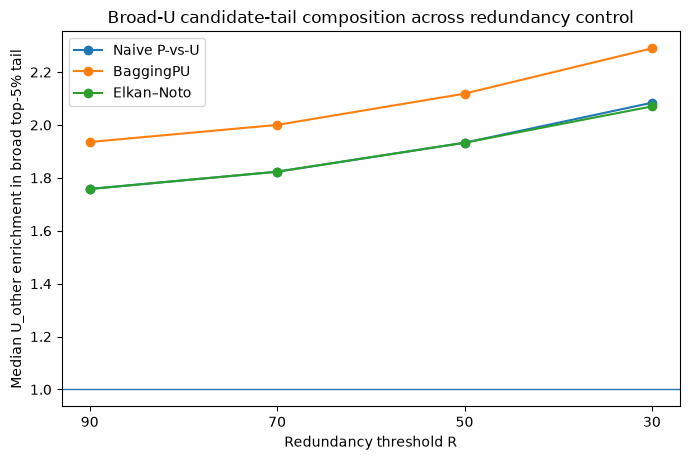

In [18]:
broad_state_by_R = (
    broad_composition.groupby(["method", "R"])
    .agg(
        n_pairs=("method", "size"),
        fraction_pairs_with_both_strata=(
            "both_U_strata_present", "mean"
        ),
        fraction_complete_state_resolution=(
            "state_resolution_complete", "mean"
        ),
        U_other_background_fraction=(
            "U_other_background_fraction", "median"
        ),
        U_other_top5_candidate_fraction=(
            "top5_candidate_other_fraction", "median"
        ),
        U_other_top5_enrichment=(
            "U_other_top5_enrichment", "median"
        ),
        other_above_explicit_U95=(
            "fraction_other_above_explicit_U95", "median"
        ),
    )
    .reset_index()
)

display(broad_state_by_R)

fig, ax = plt.subplots(figsize=(7.0, 4.7))

for method in METHODS:
    g = (
        broad_state_by_R[
            broad_state_by_R["method"].eq(method)
        ]
        .assign(order=lambda x: x["R"].map({90: 0, 70: 1, 50: 2, 30: 3}))
        .sort_values("order")
    )

    ax.plot(
        g["R"].astype(str),
        g["U_other_top5_enrichment"],
        marker="o",
        label=METHOD_LABELS[method],
    )

ax.axhline(1, linewidth=1)
ax.set_xlabel("Redundancy threshold R")
ax.set_ylabel("Median U_other enrichment in broad top-5% tail")
ax.set_title("Broad-U candidate-tail composition across redundancy control")
ax.legend()
plt.tight_layout()
plt.show()


# 18. Does broadening U change the relative gain of dedicated PU learning?


In [19]:
gain_task_rows = []

for task in TASKS:
    x = native[
        native["task"].eq(task)
    ].pivot_table(
        index=GAIN_KEYS,
        columns="method",
        values=PRIMARY,
        aggfunc="first",
    ).reset_index()

    if not set(METHODS) <= set(x.columns):
        raise RuntimeError(
            f"{task}: incomplete PU methods for gain analysis"
        )

    for method in DEDICATED_METHODS:
        tmp = x[GAIN_KEYS].copy()
        tmp["task"] = task
        tmp["method"] = method
        tmp["gain_vs_naive"] = (
            x[method] - x["naive"]
        )
        gain_task_rows.append(tmp)

gain_task = pd.concat(
    gain_task_rows,
    ignore_index=True,
)

gain_universe_rows = []

for method in DEDICATED_METHODS:
    g = gain_task[
        gain_task["method"].eq(method)
    ]

    wide = g.pivot_table(
        index=GAIN_KEYS,
        columns="task",
        values="gain_vs_naive",
        aggfunc="first",
    ).reset_index()

    tmp = wide[GAIN_KEYS].copy()
    tmp["method"] = method
    tmp["gain_conservative"] = wide["pu_conservative"]
    tmp["gain_broad"] = wide["pu_broad"]
    tmp["delta_gain_broad_minus_conservative"] = (
        wide["pu_broad"]
        - wide["pu_conservative"]
    )
    gain_universe_rows.append(tmp)

gain_universe = pd.concat(
    gain_universe_rows,
    ignore_index=True,
)

display(
    gain_universe.groupby("method")
    ["delta_gain_broad_minus_conservative"]
    .agg(
        n="size",
        mean="mean",
        median="median",
        median_abs=lambda x: x.abs().median(),
        fraction_positive=lambda x: (x > 0).mean(),
        fraction_practical_tie=lambda x: (x.abs() <= 0.02).mean(),
    )
    .reindex(DEDICATED_METHODS)
)


,n,mean,median,median_abs,fraction_positive,fraction_practical_tie
method,,,,,,
baggingpu,128,0.002140,0.001727,0.006818,0.578125,0.835938
elkan_noto,128,0.014432,0.000000,0.000000,0.296875,0.750000


# 19. Elkan–Noto propensity/clipping context


In [20]:
EN_DIAGNOSTICS = [
    c for c in [
        "U_q99",
        "U_tie_fraction_at_q99",
        "U_fraction_at_score_1",
        "P_fraction_at_score_1",
        "P_recovery_tie_component_U99",
    ]
    if c in native.columns
]

en_shift_parts = []

for metric in EN_DIAGNOSTICS:
    x = native[
        native["method"].eq("elkan_noto")
    ].pivot_table(
        index=["R", "S", "representation", "algorithm"],
        columns="task",
        values=metric,
        aggfunc="first",
    ).reset_index()

    if not set(TASKS) <= set(x.columns):
        continue

    tmp = x[
        ["R", "S", "representation", "algorithm"]
    ].copy()
    tmp["metric"] = metric
    tmp["conservative"] = x["pu_conservative"]
    tmp["broad"] = x["pu_broad"]
    tmp["delta_broad_minus_conservative"] = (
        x["pu_broad"] - x["pu_conservative"]
    )
    en_shift_parts.append(tmp)

en_universe_shift = (
    pd.concat(en_shift_parts, ignore_index=True)
    if en_shift_parts
    else pd.DataFrame()
)

if len(en_universe_shift):
    display(
        en_universe_shift.groupby("metric")
        ["delta_broad_minus_conservative"]
        .agg(
            n="size",
            mean="mean",
            median="median",
            median_abs=lambda x: x.abs().median(),
        )
    )
else:
    print(
        "No extra Elkan–Noto clipping columns available in RQ12 cache; "
        "U95/strict-U99 remain the interpretation guardrails."
    )


,n,mean,median,median_abs
metric,,,,
P_fraction_at_score_1,128,-0.042187,-0.036145,0.036145
P_recovery_tie_component_U99,128,0.013848,-0.016411,0.024251
U_fraction_at_score_1,128,0.010327,0.006943,0.006943
U_q99,128,0.050595,0.000000,0.000000
U_tie_fraction_at_q99,128,0.010063,0.007353,0.007353


# 20. Native, shared-P/native-U, and common-reference decomposition


In [21]:
native_primary_for_merge = primary_native[
    MODEL_KEYS + ["delta_broad_minus_conservative"]
].rename(
    columns={
        "delta_broad_minus_conservative":
        "native_delta_U95_broad_minus_cons"
    }
)

effect_decomposition = native_primary_for_merge.merge(
    shared_P[
        PAIR_KEYS
        + [
            "shared_P_available",
            "n_shared_P",
            "delta_shared_P_U95_broad_minus_cons",
        ]
    ],
    on=PAIR_KEYS,
    how="left",
    validate="one_to_one",
).merge(
    common_reference[
        PAIR_KEYS
        + [
            "common_reference_available",
            "n_shared_U_explicit",
            "delta_common_ref_U95_broad_minus_cons",
        ]
    ],
    on=PAIR_KEYS,
    how="left",
    validate="one_to_one",
)

effect_decomposition["native_minus_sharedP_nativeU"] = (
    effect_decomposition["native_delta_U95_broad_minus_cons"]
    - effect_decomposition["delta_shared_P_U95_broad_minus_cons"]
)

effect_decomposition["sharedP_nativeU_minus_common_reference"] = (
    effect_decomposition["delta_shared_P_U95_broad_minus_cons"]
    - effect_decomposition["delta_common_ref_U95_broad_minus_cons"]
)

effect_decomposition["native_minus_common_reference"] = (
    effect_decomposition["native_delta_U95_broad_minus_cons"]
    - effect_decomposition["delta_common_ref_U95_broad_minus_cons"]
)

display(
    effect_decomposition.groupby("method")
    .agg(
        n=("native_delta_U95_broad_minus_cons", "size"),
        n_shared_P_available=("shared_P_available", "sum"),
        n_common_reference_available=(
            "common_reference_available", "sum"
        ),
        native_delta_median=(
            "native_delta_U95_broad_minus_cons", "median"
        ),
        sharedP_nativeU_delta_median=(
            "delta_shared_P_U95_broad_minus_cons", "median"
        ),
        common_reference_delta_median=(
            "delta_common_ref_U95_broad_minus_cons", "median"
        ),
        native_minus_sharedP_nativeU_median=(
            "native_minus_sharedP_nativeU", "median"
        ),
        sharedP_nativeU_minus_common_ref_median=(
            "sharedP_nativeU_minus_common_reference", "median"
        ),
        native_minus_common_ref_median=(
            "native_minus_common_reference", "median"
        ),
    )
    .reindex(METHODS)
)


,n,n_shared_P_available,n_common_reference_available,native_delta_median,sharedP_nativeU_delta_median,common_reference_delta_median,native_minus_sharedP_nativeU_median,sharedP_nativeU_minus_common_ref_median,native_minus_common_ref_median
method,,,,,,,,,
naive,128,128,128,-0.053845,-0.057143,-0.009323,0.001413,-0.031847,-0.030687
baggingpu,128,128,128,-0.056167,-0.049752,0.000000,-0.000188,-0.048480,-0.053981
elkan_noto,128,128,128,-0.047382,-0.043987,-0.009323,0.002163,-0.026667,-0.024244


Interpretation:

- **Native:** full consequence of changing the PU task definition; both test composition and U reference can differ.
- **Shared-P/native-U:** controls the positive identities, but each task still uses its own native U distribution. A persistent delta here does **not** by itself prove that broad training changed the underlying P/explicit-U separation.
- **Common-reference:** same P and same `U_explicit` entities in both tasks. This is the cleanest contrast for a training/model effect on the original P/explicit-U problem.
- If native and shared-P/native-U are strongly negative but common-reference approaches zero, the broad penalty is driven mainly by the newly introduced, more competitive U background.
- If the common-reference delta remains strongly negative, broad training itself changes separation even after the biological evaluation reference is held fixed.


# 21. Compact RQ14 evidence table


In [22]:
def median_or_nan(df, col):
    if col not in df.columns:
        return np.nan
    return df[col].median()

evidence_rows = []

for method in METHODS:
    native_g = primary_native[
        primary_native["method"].eq(method)
    ]["delta_broad_minus_conservative"]

    p = shared_P[
        shared_P["method"].eq(method)
    ]

    u = shared_U[
        shared_U["method"].eq(method)
    ]

    cr = common_reference[
        common_reference["method"].eq(method)
    ]

    b = broad_composition[
        broad_composition["method"].eq(method)
    ]

    evidence_rows.append({
        "method": method,
        "native_broad_minus_cons_U95": native_g.median(),
        "native_practical_tie_fraction": (
            native_g.abs() <= 0.02
        ).mean(),
        "fraction_shared_P_available": (
            p["shared_P_available"].mean()
        ),
        "sharedP_nativeU_broad_minus_cons_U95": median_or_nan(
            p, "delta_shared_P_U95_broad_minus_cons"
        ),
        "shared_P_percentile_shift_nativeU": median_or_nan(
            p, "delta_shared_P_percentile_broad_minus_cons"
        ),
        "shared_P_score_spearman": median_or_nan(
            p, "shared_P_score_spearman"
        ),
        "fraction_common_reference_available": (
            cr["common_reference_available"].mean()
        ),
        "common_reference_broad_minus_cons_U95": median_or_nan(
            cr, "delta_common_ref_U95_broad_minus_cons"
        ),
        "common_reference_broad_minus_cons_U99": median_or_nan(
            cr, "delta_common_ref_U99_broad_minus_cons"
        ),
        "common_reference_broad_minus_cons_strict_U99": median_or_nan(
            cr, "delta_common_ref_strict_U99_broad_minus_cons"
        ),
        "common_reference_P_percentile_shift": median_or_nan(
            cr, "delta_common_ref_P_percentile_broad_minus_cons"
        ),
        "fraction_shared_U_available": (
            u["shared_U_available"].mean()
        ),
        "shared_U_score_spearman": median_or_nan(
            u, "shared_U_score_spearman"
        ),
        "shared_U_top5_jaccard": median_or_nan(
            u, "top5_shared_U_jaccard"
        ),
        "shared_U_top1_jaccard": median_or_nan(
            u, "top1_shared_U_jaccard"
        ),
        "shared_U_top1_overlap": median_or_nan(
            u, "top1_shared_U_overlap_coefficient"
        ),
        "fraction_pairs_with_both_U_strata": (
            b["both_U_strata_present"].mean()
        ),
        "fraction_pairs_with_complete_U_state_resolution": (
            b["state_resolution_complete"].mean()
        ),
        "U_other_background_fraction": median_or_nan(
            b, "U_other_background_fraction"
        ),
        "U_other_top5_candidate_fraction": median_or_nan(
            b, "top5_candidate_other_fraction"
        ),
        "U_other_top5_enrichment": median_or_nan(
            b, "U_other_top5_enrichment"
        ),
    })

rq14_evidence = pd.DataFrame(evidence_rows)
display(rq14_evidence)


,method,native_broad_minus_cons_U95,native_practical_tie_fraction,fraction_shared_P_available,sharedP_nativeU_broad_minus_cons_U95,shared_P_percentile_shift_nativeU,shared_P_score_spearman,fraction_common_reference_available,common_reference_broad_minus_cons_U95,common_reference_broad_minus_cons_U99,common_reference_broad_minus_cons_strict_U99,common_reference_P_percentile_shift,fraction_shared_U_available,shared_U_score_spearman,shared_U_top5_jaccard,shared_U_top1_jaccard,shared_U_top1_overlap,fraction_pairs_with_both_U_strata,fraction_pairs_with_complete_U_state_resolution,U_other_background_fraction,U_other_top5_candidate_fraction,U_other_top5_enrichment
0,naive,-0.053845,0.218750,1.0,-0.057143,-0.004147,0.920087,1.0,-0.009323,-0.014354,-0.014354,-0.000069,1.0,0.837964,0.473393,0.460317,0.630435,1.0,1.0,0.287739,0.529816,1.898443
1,baggingpu,-0.056167,0.257812,1.0,-0.049752,-0.004198,0.946525,1.0,0.000000,0.000000,0.000000,0.000000,1.0,0.928571,0.626501,0.533657,0.695927,1.0,1.0,0.287739,0.577393,2.068104
2,elkan_noto,-0.047382,0.250000,1.0,-0.043987,0.000000,0.853047,1.0,-0.009323,-0.024126,0.000000,0.000000,1.0,0.837964,0.473393,0.480552,0.663551,1.0,1.0,0.287739,0.528894,1.896200


# 22. RQ14 synthesis questions


After execution, RQ14 should answer:

1. How much larger is the broad unlabeled universe after each redundancy threshold?
2. Are the Stage-07 positive Core and `U_explicit` strata exactly preserved across conservative and broad tasks?
3. How much do Stage-08 outer-test assignments diverge after `U_other_unresolved` is added?
4. Does broad U change native U95 positive recovery?
5. Does that conclusion persist across PU methods?
6. Does the native universe effect change systematically with R or S?
7. On the **same P_core outer-test proteins but native U references**, does broadening U alter U95 recovery or positive percentile position?
8. On the same positives, are raw score rankings preserved?
9. When both **P_core and U_explicit identities are held fixed**, does a conservative-vs-broad separation penalty remain?
10. Does the common-reference conclusion persist at U99 and strict-U99?
11. On the **same U_explicit outer-test proteins**, are rankings stable across conservative and broad tasks?
12. Does broadening U materially change the tie-aware top-5% and top-1% candidate sets among shared explicit-U proteins?
13. Within broad U, are `U_other_unresolved` proteins systematically higher- or lower-scoring than `U_explicit`?
14. Are `U_other_unresolved` proteins enriched or depleted in the broad top-5% candidate tail?
15. Does that enrichment change as redundancy control becomes stringent?
16. Does the broad universe change the relative gain of BaggingPU or Elkan–Noto versus naive P-vs-U?
17. Does Elkan–Noto clipping/tie behavior change when U is broadened?
18. How much of the native broad penalty remains after controlling P composition, and how much remains after controlling both P and U identities?
19. How often are shared-U, common-reference, or two-stratum comparisons not estimable because of Stage-08 topology?

The useful conclusion is **not**:

> “Broad U is better/worse.”

The useful conclusion is whether **the biological scope assigned to the unknown class changes the learned ranking problem and the downstream discovery space**, and whether that effect arises from altered model behavior, a more competitive U reference, or both.


## Manuscript-level conceptual target

If supported:

> **The definition of the unlabeled universe is itself a modeling choice. Expanding U from explicitly unresolved proteins to a broader open-world background can alter the score landscape, the recovery of known positives, and the proteins prioritized for follow-up even though the positive Core is unchanged.**

The common-reference analysis determines which stronger interpretation is justified:

- If the common-reference penalty is small, the main effect of broad U is the introduction of a more competitive candidate-like unknown background.
- If it remains large, broad training itself changes separation within the original P/explicit-U problem.

A particularly strong result would be:

> **Broadening U reshapes candidate prioritization more strongly than the score organization of already annotated positives, indicating that uncertainty-set definition primarily changes the discovery problem.**

Broader methodological point:

> **In positive–unlabeled protein learning, “unlabeled” is not a neutral container: the biological scope used to construct U determines the alternatives against which candidate-likeness is learned.**


# 23. Export RQ14 cache tables


In [23]:
UNIVERSE_PATH = CACHE_DIR / "rq14_U_universe_composition.tsv"
IDENTITY_PATH = CACHE_DIR / "rq14_shared_stage07_strata_identity.tsv"
BREADTH_PATH = CACHE_DIR / "rq14_U_universe_breadth.tsv"
NATIVE_PATH = CACHE_DIR / "rq14_native_universe_contrasts.tsv"
TEST_OVERLAP_PATH = CACHE_DIR / "rq14_outer_test_overlap.tsv"
SHARED_P_PATH = CACHE_DIR / "rq14_shared_positive_effects.tsv"
SHARED_U_PATH = CACHE_DIR / "rq14_shared_explicitU_effects.tsv"
COMMON_REF_PATH = CACHE_DIR / "rq14_common_reference_effects.tsv"
BROAD_COMP_PATH = CACHE_DIR / "rq14_broad_U_state_score_composition.tsv"
GAIN_PATH = CACHE_DIR / "rq14_method_gain_universe_shift.tsv"
EN_PATH = CACHE_DIR / "rq14_elkan_noto_universe_shift.tsv"
NATIVE_SHARED_PATH = CACHE_DIR / "rq14_native_shared_common_reference_decomposition.tsv"
EVIDENCE_PATH = CACHE_DIR / "rq14_evidence_summary.tsv"
JOIN_QC_PATH = CACHE_DIR / "rq14_score_metadata_join_qc.tsv"
AVAILABILITY_PATH = CACHE_DIR / "rq14_estimability_audit.tsv"

exports = {
    UNIVERSE_PATH: universe_composition,
    IDENTITY_PATH: universe_identity,
    BREADTH_PATH: breadth,
    NATIVE_PATH: native_contrasts,
    TEST_OVERLAP_PATH: test_overlap,
    SHARED_P_PATH: shared_P,
    SHARED_U_PATH: shared_U,
    COMMON_REF_PATH: common_reference,
    BROAD_COMP_PATH: broad_composition,
    GAIN_PATH: gain_universe,
    EN_PATH: en_universe_shift,
    NATIVE_SHARED_PATH: effect_decomposition,
    EVIDENCE_PATH: rq14_evidence,
    JOIN_QC_PATH: score_metadata_join_qc,
    AVAILABILITY_PATH: availability,
}

for path, frame in exports.items():
    frame.to_csv(
        path,
        sep="\t",
        index=False,
    )

print("Saved:")
for path in exports:
    print(" ", path)


Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq14_U_universe_composition.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq14_shared_stage07_strata_identity.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq14_U_universe_breadth.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq14_native_universe_contrasts.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq14_outer_test_overlap.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/notebook_cache/rq14_shared_positive_effects.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_pu/noteboo

## Final interpretation guardrails

Before writing RQ14 into the manuscript:

- inspect `rq14_estimability_audit.tsv`;
- report how often shared-U, common-reference, and two-stratum comparisons were estimable;
- never convert an absent outer-test stratum into a zero biological effect;
- use native-universe effects for the **whole task-definition consequence**;
- use shared-P/native-U effects only to control positive test composition — they still use different U reference distributions;
- use `rq14_common_reference_effects.tsv` to assess whether broad training changes separation on the exact same P and exact same explicit-U proteins;
- use shared explicit-U ranking plus tie-aware top-5% **and top-1%** overlap for discovery-space stability;
- interpret `U_other_unresolved` enrichment only where state resolution is complete;
- keep Elkan–Noto U99 claims subordinate to strict-U99 / clipping diagnostics.

The notebook should finish even when some Stage-08 cells contain zero shared `U_explicit` proteins or only one broad-U stratum. Those are results about split topology, not pipeline failures.

Most importantly, do not attribute a negative shared-P/native-U delta automatically to altered model behavior. Only the common-reference contrast holds both biological sides of the evaluation fixed.
